# FintechGuard — EDA do TP2

## Problema

Este notebook aprofunda a Hipótese 4 formulada no TP1: clientes associados a valores mais altos de `First Response Time` podem apresentar menor satisfação. A variável representa o **horário** da primeira resposta, não a duração da espera. A análise testa uma associação exploratória e não permite inferir causalidade.

## Dados

Fonte: `data/customer_support_tickets.csv`. Removemos linhas totalmente vazias e duplicatas exatas, normalizamos categorias e identificamos registros estruturais pela regra adotada no script de EDA. Texto sinalizado como possível HTML/JavaScript permanece nos dados e requer revisão contextual.

In [1]:
from pathlib import Path
from html import unescape
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "data/customer_support_tickets.csv").exists():
        ROOT = candidate
        break
DATA_PATH = ROOT / "data/customer_support_tickets.csv"
assert DATA_PATH.exists(), f"Dataset não encontrado: {DATA_PATH}"
df_original = pd.read_csv(DATA_PATH)
df = df_original.dropna(how="all").drop_duplicates().copy()
df["Ticket Type"] = df["Ticket Type"].replace({"Cobrança": "Billing inquiry", "Suporte Técnico": "Technical issue"})
text_columns = [c for c in ["Customer Name", "Customer Email", "Product Purchased", "Ticket Type", "Ticket Subject", "Ticket Description", "Ticket Status", "Resolution", "Ticket Priority", "Ticket Channel"] if c in df.columns]
text_for_audit = df[text_columns].fillna("").astype(str).apply(lambda col: col.map(unescape))
suspicious_payloads = text_for_audit.apply(
    lambda col: col.str.contains(r"<\s*script\b", case=False, regex=True, na=False)
).any(axis=1)
string_count = text_for_audit.apply(lambda col: col.str.strip().str.lower().eq("string")).sum(axis=1)
age = pd.to_numeric(df["Customer Age"], errors="coerce")
structural_anomalies = (string_count >= 3) & (age == 120)
df = df.loc[~structural_anomalies].copy()
df["Customer Age"] = pd.to_numeric(df["Customer Age"], errors="coerce")
df["Customer Satisfaction Rating"] = pd.to_numeric(df["Customer Satisfaction Rating"], errors="coerce")
first_response = pd.to_datetime(df["First Response Time"], errors="coerce")
df["First Response Minutes"] = first_response.dt.hour * 60 + first_response.dt.minute + first_response.dt.second / 60
print(f"Linhas originais: {len(df_original):,}")
print(f"Linhas após vazios/duplicatas: {len(df_original.dropna(how='all').drop_duplicates()):,}")
print(f"Anomalias estruturais removidas: {int(structural_anomalies.sum()):,}")
print(f"Registros na análise: {len(df):,}")
print(f"Registros sinalizados por padrão semelhante a HTML/JavaScript (mantidos): {int(suspicious_payloads.sum()):,}")

Linhas originais: 8,484
Linhas após vazios/duplicatas: 8,480
Anomalias estruturais removidas: 7
Registros na análise: 8,473
Registros sinalizados por padrão semelhante a HTML/JavaScript (mantidos): 8


## Análise

As contagens e estatísticas abaixo são calculadas a partir dos dados carregados. Valores ausentes permanecem ausentes quando a análise não exige preenchimento.

In [2]:
columns = ["Ticket Type", "Customer Age", "First Response Time", "Customer Satisfaction Rating"]
print("Valores ausentes:")
print(df[columns].isna().sum().to_string())
print("\nDistribuição de Ticket Type:")
print(df["Ticket Type"].value_counts(dropna=False).to_string())
print("\nEstatísticas descritivas:")
print(df[["Customer Age", "First Response Minutes", "Customer Satisfaction Rating"]].describe().round(2).to_string())

Valores ausentes:
Ticket Type                        0
Customer Age                       0
First Response Time             2819
Customer Satisfaction Rating    5700

Distribuição de Ticket Type:
Ticket Type
Refund request          1752
Technical issue         1750
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1635

Estatísticas descritivas:
       Customer Age  First Response Minutes  Customer Satisfaction Rating
count       8473.00                 5650.00                       2773.00
mean          44.02                  721.70                          2.99
std           15.30                  418.11                          1.41
min           18.00                    0.33                          1.00
25%           31.00                  357.43                          2.00
50%           44.00                  719.22                          3.00
75%           57.00                 1092.50                          4.00
max           70.00         

### Heatmap de correlação (Seaborn)

O heatmap resume correlações lineares entre idade, horário da primeira resposta (minutos desde meia-noite) e satisfação. Correlação próxima de zero indica associação linear fraca nesta amostra; não prova independência nem causalidade.

                              Customer Age  First Response Minutes  Customer Satisfaction Rating
Customer Age                         1.000                   0.015                        -0.005
First Response Minutes               0.015                   1.000                        -0.040
Customer Satisfaction Rating        -0.005                  -0.040                         1.000


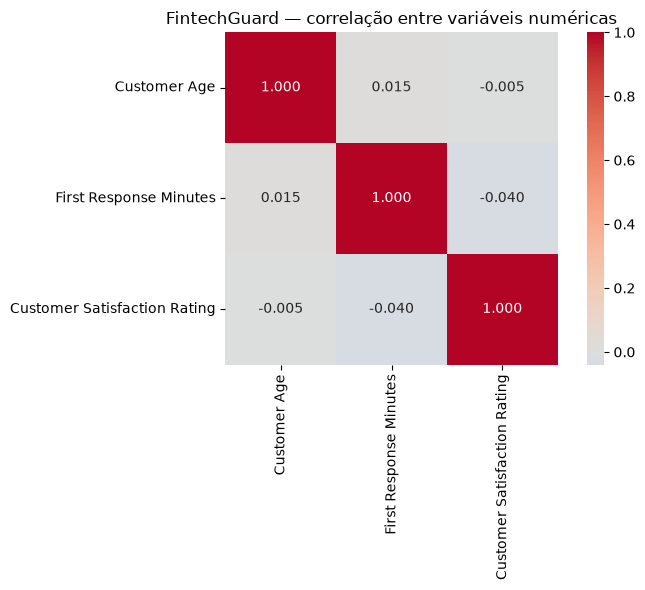

In [3]:
numeric_columns = ["Customer Age", "First Response Minutes", "Customer Satisfaction Rating"]
corr = df[numeric_columns].corr(numeric_only=True)
print(corr.round(3).to_string())
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", center=0, square=True)
plt.title("FintechGuard — correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

### Teste formal — Mann–Whitney U

**H0:** as distribuições de satisfação dos grupos com horário de primeira resposta abaixo e acima da mediana não diferem.

**H1:** as distribuições diferem.

Teste bilateral, sem pressupor normalidade; α = 0,05. Como a variável representa horário, a hipótese é interpretada como comparação entre horários, e não como efeito do tempo de espera.

In [4]:
test_data = df[["First Response Minutes", "Customer Satisfaction Rating"]].dropna()
median_time = test_data["First Response Minutes"].median()
early = test_data.loc[test_data["First Response Minutes"] <= median_time, "Customer Satisfaction Rating"]
late = test_data.loc[test_data["First Response Minutes"] > median_time, "Customer Satisfaction Rating"]
u_stat, p_value = mannwhitneyu(early, late, alternative="two-sided")
alpha = 0.05
print(f"Mediana do horário: {median_time:.2f} minutos desde 00:00")
print(f"Horário mais cedo: n={len(early):,}; mediana de satisfação={early.median():.2f}")
print(f"Horário mais tarde: n={len(late):,}; mediana de satisfação={late.median():.2f}")
print(f"Mann–Whitney U={u_stat:,.2f}; p={p_value:.6f}; α={alpha:.2f}")
print("Decisão: não rejeitar H0." if p_value >= alpha else "Decisão: rejeitar H0.")

Mediana do horário: 710.20 minutos desde 00:00
Horário mais cedo: n=1,385; mediana de satisfação=3.00
Horário mais tarde: n=1,384; mediana de satisfação=3.00
Mann–Whitney U=994,174.50; p=0.082766; α=0.05
Decisão: não rejeitar H0.


## Insights

Se p > 0,05, os dados não fornecem evidência suficiente de diferença entre as distribuições de satisfação dos grupos definidos por horário. Isso não prova que as distribuições sejam iguais, nem mostra que uma resposta mais rápida cause maior satisfação. O heatmap resume associações lineares; Mann–Whitney compara distribuições entre dois grupos.

## Próximos passos — ligação ao TP3

O TP3 prevê `Ticket Type` a partir do texto. Use `Ticket Subject` e `Ticket Description` como features textuais (por exemplo, TF‑IDF) e `Ticket Type` como target. Remova registros sem target, faça divisão estratificada sem duplicatas entre partições e compare baseline e classificadores com F1 macro, matriz de confusão e métricas por classe. Variáveis posteriores ao atendimento, como `Resolution` e satisfação, não devem ser features se não estiverem disponíveis na previsão.

## Limitações

A base é observacional e a variável temporal representa horário. A análise não controla fatores de confusão nem sustenta causalidade. A regra de anomalias estruturais segue o script existente.